In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, recall_score, classification_report

FUNCTIONS

In [61]:
def plot_rolling_trend(df, columns, window=12, center=True,
                       labels=None, title=None, ylabel=None,
                       figsize=(14, 4)):
    """Plot the rolling mean of one or several monthly columns.

    columns : str or list of column names
    window  : rolling window in months
    labels  : optional dict {column: legend label}
    """
    if isinstance(columns, str):
        columns = [columns]
    labels = labels or {}

    d = df.sort_values("month").copy()
    fig, ax = plt.subplots(figsize=figsize)

    for col in columns:
        roll_col = f"{col}_roll{window}"
        d[roll_col] = d[col].rolling(window, center=center).mean()
        sns.lineplot(x="month", y=roll_col, data=d, ax=ax, linewidth=2,
                     label=labels.get(col, f"{col} ({window}-month mean)"))

    ax.set_title(title or f"{window}-month rolling mean")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel or "")
    ax.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
def show_quinquennial_temperature_tendencies(df)

#### Paths

In [10]:
power_folder = '../data/processed/power_dataset/'

## 1. Individual EDAs

### 1.1 Écija region
NASA/POWER Source Native Resolution Daily Data 
Dates (month/day/year): 01/01/1981 through 10/31/2026 in UTC


The value for missing source data that cannot be computed or is outside of the sources availability range: -999 
parameter(s): 

T2M                   MERRA-2 Temperature at 2 Meters (C)

T2M_MAX               MERRA-2 Temperature at 2 Meters Maximum (C) 

T2M_MIN               MERRA-2 Temperature at 2 Meters Minimum (C) 

PRECTOTCORR           MERRA-2 Precipitation Corrected (mm/day)

RH2M                  MERRA-2 Relative Humidity at 2 Meters (%) 

WS2M                  MERRA-2 Wind Speed at 2 Meters (m/s)

GWETROOT              MERRA-2 Root Zone Soil Wetness (1)

GWETTOP               MERRA-2 Surface Soil Wetness (1) 

In [22]:
écija_power_monthly_path = os.path.join(power_folder, 'monthly/écija_monthly.csv')
écija_power_daily_path = os.path.join(power_folder, 'daily/écija_daily.csv')
écija_monthly = pd.read_csv(écija_power_monthly_path)
écija_daily = pd.read_csv(écija_power_daily_path)

In [15]:
écija_monthly.info()

<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   month           550 non-null    str    
 1   t2m_mean        550 non-null    float64
 2   t2m_max_mean    550 non-null    float64
 3   t2m_max_peak    550 non-null    float64
 4   t2m_min_mean    550 non-null    float64
 5   t2m_min_low     550 non-null    float64
 6   precip_mm       550 non-null    float64
 7   rain_days       550 non-null    int64  
 8   rh_mean         550 non-null    float64
 9   wind_mean       550 non-null    float64
 10  soil_root_mean  550 non-null    float64
 11  soil_top_mean   550 non-null    float64
 12  frost_days      550 non-null    int64  
 13  heat_days       550 non-null    int64  
 14  valid_days      550 non-null    int64  
dtypes: float64(10), int64(4), str(1)
memory usage: 64.6 KB


In [16]:
écija_monthly.columns

Index(['month', 't2m_mean', 't2m_max_mean', 't2m_max_peak', 't2m_min_mean',
       't2m_min_low', 'precip_mm', 'rain_days', 'rh_mean', 'wind_mean',
       'soil_root_mean', 'soil_top_mean', 'frost_days', 'heat_days',
       'valid_days'],
      dtype='str')

#### 1.1.1 Tendency of temperature changes from 1981 to 2026

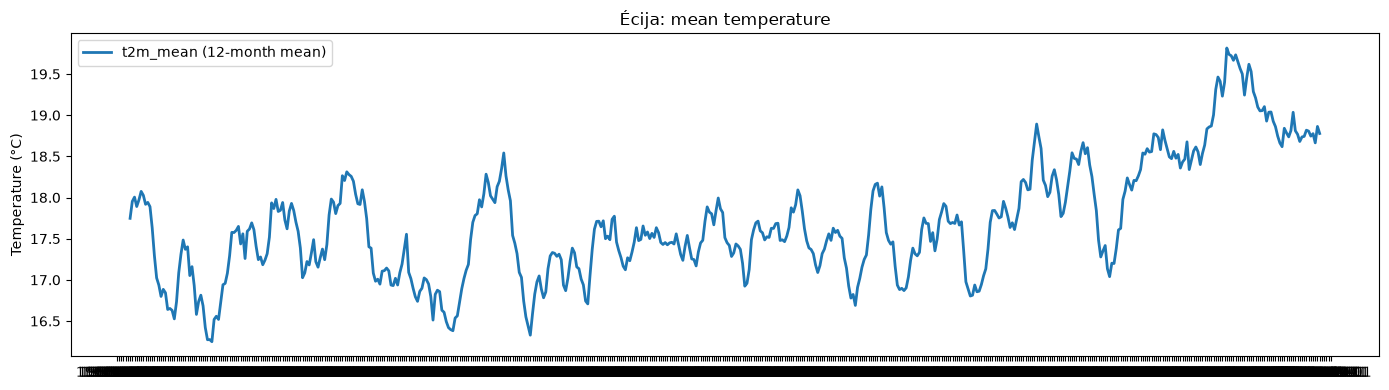

In [63]:
plot_rolling_trend(écija_monthly, "t2m_mean", title="Écija: mean temperature", ylabel="Temperature (°C)")